# EEE3032 – Computer Vision and Pattern Recognition
## Coursework starter: Visual Search of an Image Collection

This notebook provides a **working baseline and evaluation framework**. The core assessed task is one focused scientific investigation: formulate a question, implement a controlled change, select parameters on development queries, evaluate once on the held-out test set, and explain what the evidence means.

### Evaluation discipline
- `gallery`: the searchable database and the only images that may be used to **fit** data-dependent representations (for example PCA or a visual vocabulary).
- `dev`: use these queries to compare variants and choose parameters.
- `test`: reserve these queries for the final reported comparison. Do not repeatedly inspect test performance while developing your method.

The supplied baseline is a global RGB histogram with Euclidean distance. It verifies that your pipeline works; simply reproducing it is not a substantial coursework contribution.

The expected core workload is approximately **15–18 hours**; you should not need to exceed **20 hours**. Do not add algorithms merely to make the project larger.


In [15]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3
!ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3
cvpr					 requirements-deep.txt
EEE3032_Coursework_Starter.ipynb	 requirements.txt
EEE3032_Optional_Deep_Descriptors.ipynb  run_baseline.py
precompute_deep_descriptors.py		 split_manifest.csv
README.md				 student_methods.py


In [16]:
!cp -r /content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2 /content/

In [17]:
from pathlib import Path
DATASET_SOURCE = Path("/content/MSRC_ObjCategImageDatabase_v2")

In [18]:
# Portable setup: standard Jupyter / University PCs / Google Colab
import sys, subprocess, importlib.util
from pathlib import Path

required = {
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "cv2": "opencv-python-headless",
}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

# Make sure the supplied local helper package can be imported.
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
from functools import partial

from cvpr.dataset import load_split_records
from cvpr.baseline import global_rgb_histogram
from cvpr.retrieval import compute_descriptors
from cvpr.evaluation import evaluate_retrieval, per_category_summary, top1_confusion_matrix
from cvpr.plotting import show_ranked_results, plot_confusion_matrix

try:
    import google.colab  # noqa
    print("Environment: Google Colab")
except ImportError:
    print("Environment: standard Jupyter/Python")

Environment: Google Colab


## 1. Point the notebook at the MSRC-v2 dataset

Set `DATASET_SOURCE` to either:
- the extracted `MSRC_ObjCategImageDatabase_v2` folder, or
- the supplied MSRC dataset `.zip` file.

If you use the ZIP file, the helper code extracts it into the local `data/` folder automatically.

In [19]:
DATASET_SOURCE = Path("/content/MSRC_ObjCategImageDatabase_v2")

if not DATASET_SOURCE.exists():
    raise FileNotFoundError(f"{DATASET_SOURCE} not found. Re-run the cp cell.")

MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, test = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)

print("Dataset source:", DATASET_SOURCE)
print(f"Gallery images: {len(gallery)}")
print(f"Development queries: {len(dev)}")
print(f"Final test queries: {len(test)}")

Dataset source: /content/MSRC_ObjCategImageDatabase_v2
Gallery images: 391
Development queries: 100
Final test queries: 100


## 2. Supplied baseline

The baseline uses a global 3-D RGB colour histogram and Euclidean distance. Start by reproducing the baseline result on the development queries.

You may vary baseline parameters during exploration, but your coursework should go beyond parameter tweaking and test well-motivated alternatives.

In [20]:
BASELINE_BINS = 4
descriptor_fn = partial(global_rgb_histogram, bins_per_channel=BASELINE_BINS)

gallery_features = compute_descriptors(gallery, descriptor_fn)
dev_features = compute_descriptors(dev, descriptor_fn)

print("Descriptor matrix:", gallery_features.shape)

Descriptor matrix: (391, 64)


In [21]:
dev_summary, dev_rows = evaluate_retrieval(
    dev, dev_features, gallery, gallery_features, k=10
)

print(f"Development mAP:      {dev_summary['mAP']:.4f}")
print(f"Development mean P@10: {dev_summary['mean_P@10']:.4f}")

Development mAP:      0.1592
Development mean P@10: 0.1830


In [22]:
# Per-category results help reveal where a method works and where it fails.
category_rows = per_category_summary(dev_rows, k=10)
for row in category_rows:
    print(
        f"Group {row['category']:>2}: "
        f"mAP={row['mAP']:.4f}, P@10={row['mean_P@10']:.4f}"
    )

Group  1: mAP=0.1907, P@10=0.3400
Group  2: mAP=0.2989, P@10=0.4000
Group  3: mAP=0.1014, P@10=0.0400
Group  4: mAP=0.1423, P@10=0.1200
Group  5: mAP=0.1365, P@10=0.2200
Group  6: mAP=0.1386, P@10=0.1200
Group  7: mAP=0.2331, P@10=0.2600
Group  8: mAP=0.1528, P@10=0.1400
Group  9: mAP=0.3382, P@10=0.4200
Group 10: mAP=0.1211, P@10=0.0400
Group 11: mAP=0.0529, P@10=0.0400
Group 12: mAP=0.0982, P@10=0.1400
Group 13: mAP=0.4026, P@10=0.5200
Group 14: mAP=0.0770, P@10=0.1000
Group 15: mAP=0.0805, P@10=0.0600
Group 16: mAP=0.0743, P@10=0.0600
Group 17: mAP=0.2372, P@10=0.3000
Group 18: mAP=0.1057, P@10=0.1600
Group 19: mAP=0.1394, P@10=0.1400
Group 20: mAP=0.0626, P@10=0.0400


## 3. Inspect retrieval examples

Do not show only impressive examples. Your report should use retrieval examples to explain both strengths and systematic failure modes.

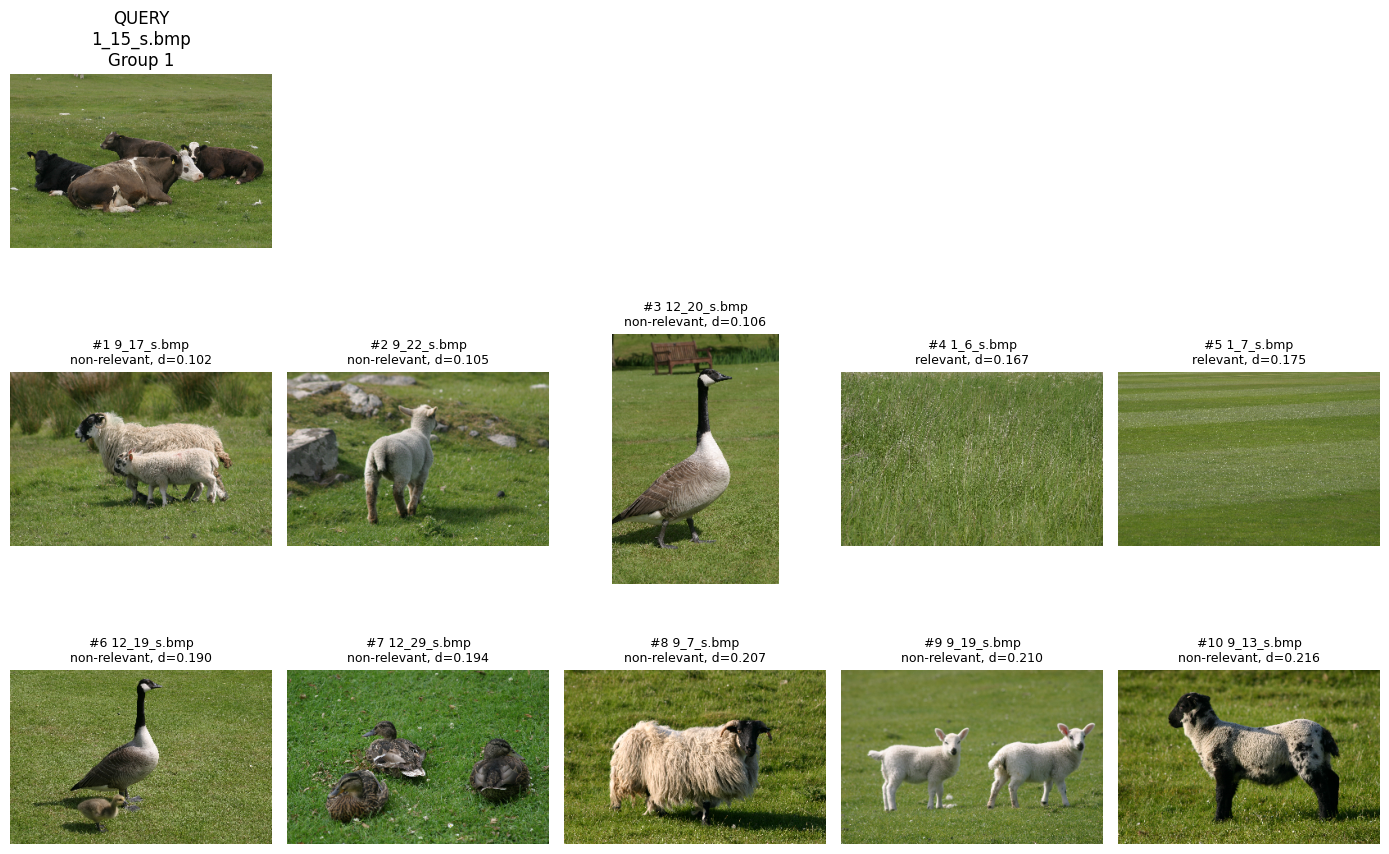

In [23]:
QUERY_INDEX = 0
show_ranked_results(
    dev[QUERY_INDEX],
    dev_features[QUERY_INDEX],
    gallery,
    gallery_features,
    top_k=10,
)
plt.show()

## 4. Your focused core investigation

Before coding, state **one research question or hypothesis**. A single question may involve several controlled variants. For example:

> A global colour histogram ignores spatial layout. A spatially divided colour descriptor may improve retrieval for groups whose appearance depends on where colours occur, but may become more sensitive to object position.

Then design a controlled experiment that changes the relevant factor while keeping the rest of the pipeline fixed.

Possible directions include colour representation/quantisation, spatial layout, texture or edge information, feature normalisation, distance measures, dimensionality reduction, local features, feature fusion, or another justified representation. These are **suggestions, not a checklist**.

Your core method must include a representation or retrieval method that you design or modify yourself. The optional supplied deep descriptors do not replace this requirement.


In [24]:
# Example structure for one investigation.
# You may put your implementation in student_methods.py or define it in the notebook.

# from student_methods import extract_descriptor, distance
# gallery_features_method1 = compute_descriptors(gallery, extract_descriptor)
# dev_features_method1 = compute_descriptors(dev, extract_descriptor)
# summary_method1, rows_method1 = evaluate_retrieval(
#     dev, dev_features_method1, gallery, gallery_features_method1,
#     distance_fn=distance,
#     k=10,
# )
# summary_method1

## 5. Data-dependent methods: avoid leakage

If your method learns anything from data — for example:
- PCA / whitening,
- feature scaling statistics,
- a visual vocabulary / k-means codebook,
- any learned model,

fit it using **gallery images only**. Then transform the gallery, development queries and test queries using the fitted transformation.

Use the development queries to choose parameters. The final test set is for the final comparison, not iterative tuning.

## 6. Final test evaluation

Set `RUN_FINAL_TEST=True` only when you have chosen your final core method using the development set. Report the same retrieval metrics on the held-out test queries.

For the final selected method, also create the **top-1 category confusion matrix**. Rows are the true query group and columns are the group of the top-ranked retrieved image. Your report should interpret important confusions rather than merely display the matrix.


In [25]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    # Replace descriptor_fn/gallery_features below with your FINAL selected method.
    test_features = compute_descriptors(test, descriptor_fn)
    test_summary, test_rows = evaluate_retrieval(
        test, test_features, gallery, gallery_features, k=10
    )
    print(f"TEST mAP:       {test_summary['mAP']:.4f}")
    print(f"TEST mean P@10: {test_summary['mean_P@10']:.4f}")

    cm, cm_categories = top1_confusion_matrix(
        test, test_features, gallery, gallery_features
    )
    plot_confusion_matrix(cm, cm_categories, normalize=True)
    plt.show()
else:
    print("Final test evaluation is locked. Keep RUN_FINAL_TEST=False while developing.")


Final test evaluation is locked. Keep RUN_FINAL_TEST=False while developing.


## What to retain for your report

For the core investigation, record:
- the research question/hypothesis and what changed relative to the baseline;
- descriptor dimensionality and important parameter values;
- development mAP and mean P@10 for the controlled variants;
- final test mAP and mean P@10 for the selected method;
- per-category behaviour;
- the final top-1 category confusion matrix and your interpretation of important confusions;
- at least four representative ranked visual-search examples, including successes and failures/ambiguous cases;
- an explanation of *why* the results changed, not merely whether the score went up or down.

Large retrieval grids may be placed in the report appendix, but they must be discussed in the main text. The complete report, including appendices, must fit within the stated 10-page limit (title page and references excluded).


## Optional extensions

Two optional extensions are available in the coursework specification:

- **Personal category (+10):** test your frozen core system on 20 photographs of a new category (15 gallery / 5 query split).
- **Deep descriptors (+10):** use the separate `EEE3032_Optional_Deep_Descriptors.ipynb` notebook to investigate one or both supplied pretrained encoders.

The core coursework can receive 100% without either extension.
